# Упражнения по регуляризации и методу градиентного спуска
![UnderOverFit.png](Assets/UnderOverFit.png)


# Учебные цели

- Объяснить суть функций затрат, регуляризации, выбора признаков и гиперпараметров
- Охарактеризовать сложные алгоритмы статистической оптимизации, такие как метод градиентного спуска, и его применение в линейной регрессии
- Применять расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения


## Введение

Мы начнём с краткого введения в регрессию, полиномиальные признаки и регуляризацию на примере очень простого набора разреженных данных, содержащего столбец данных `x` и соответствующие данные `y` с шумом. Файл данных называется `X_Y_Sinusoid_Data.csv`.

In [1]:
import os
import warnings

from sklearnex import patch_sklearn

patch_sklearn()

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import ElasticNetCV, Lasso, LassoCV, LinearRegression, Ridge, RidgeCV, SGDRegressor
from sklearn.metrics import make_scorer, mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures

data_path = ['data']

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные.

* Также сгенерируйте примерно 100 равномерно распределенных точек данных по оси x в диапазоне от 0 до 1. Используя эти точки, вычислите данные по оси y, представляющие «истинное значение» (реальную функцию), по уравнению: $y = \sin(2\pi x)$

* Постройте график разреженных данных (`x` против `y`) и вычисленных («реальных») данных.



In [2]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['X_Y_Sinusoid_Data.csv'])
data = pd.read_csv(filepath)

X_real = np.linspace(0, 1.0, 100)
Y_real = np.sin(2 * np.pi * X_real)

data.describe()

,x,y
count,20.000000,20.000000
mean,0.484707,0.122838
std,0.267591,0.802220
min,0.038571,-1.128250
25%,0.277753,-0.582809
50%,0.457273,0.282361
75%,0.698909,0.677734
max,0.950964,1.264121


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

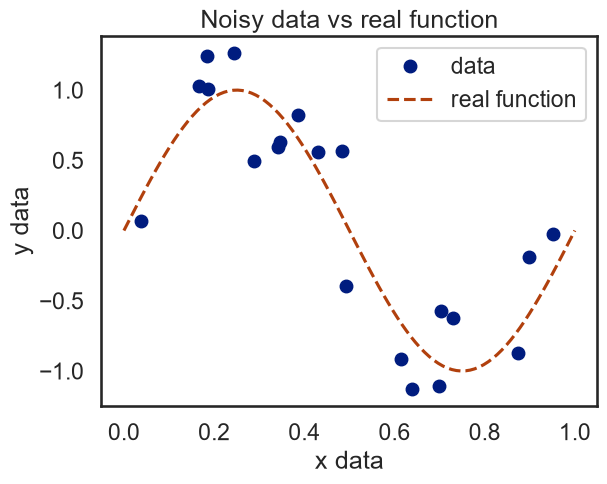

In [4]:
sns.set_style('white')
sns.set_context('talk')
sns.set_palette('dark')

ax = data.set_index('x')['y'].plot(ls='', marker='o', label='data')
ax.plot(X_real, Y_real, ls='--', marker='', label='real function')

ax.legend()
ax.set(xlabel='x data', ylabel='y data', title='Noisy data vs real function');

Вывод: я загрузил 20 точек из файла X_Y_Sinusoid_Data.csv, x у них лежит от 0.04 до 0.95, и построил 100 точек истинной функции y = sin(2πx) на отрезке от 0 до 1. На графике точки разбросаны вокруг синусоиды, но заметно от неё отклоняются, потому что в данных есть шум. Точек мало, и они расположены неравномерно, например между 0.04 и 0.17 нет ни одной. Поэтому на этих данных хорошо видно, как сложная модель подстраивается под шум (задания 2 и 3).

## Вопрос 2


* Используя класс `PolynomialFeatures` из библиотеки предварительной обработки данных Scikit-learn, создайте полиномиальные признаки 20-го порядка.
* Проведите линейную регрессию по этим данным.
* Постройте график, на котором будут отображены полученные прогнозируемые значения в сравнении с расчётными данными.

Обратите внимание, что для класса `PolynomialFeatures` требуется либо датафрейм (с одним столбцом, а не серия), либо двумерный массив размером (`X`, 1), где `X` — длина.

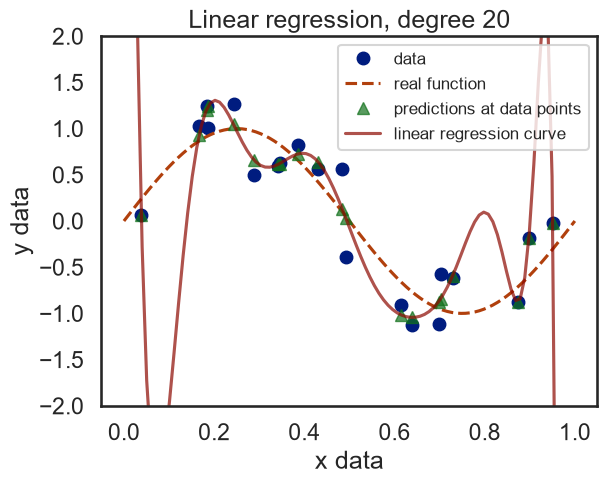

In [5]:
degree = 20
pf = PolynomialFeatures(degree)

X_data = data[['x']].to_numpy()
Y_data = data['y'].to_numpy()

X_poly = pf.fit_transform(X_data)
X_real_poly = pf.transform(X_real.reshape(-1, 1))

lr = LinearRegression().fit(X_poly, Y_data)
Y_pred = lr.predict(X_poly)

plt.plot(X_data, Y_data, marker='o', ls='', label='data')
plt.plot(X_real, Y_real, ls='--', label='real function')
plt.plot(X_data, Y_pred, marker='^', ls='', alpha=.7, label='predictions at data points')
plt.plot(X_real, lr.predict(X_real_poly), alpha=.7, label='linear regression curve')
plt.ylim(-2, 2)
plt.legend(fontsize='x-small')
plt.gca().set(xlabel='x data', ylabel='y data', title=f'Linear regression, degree {degree}');

Вывод: я построил полиномиальные признаки 20-й степени, получился 21 признак вместе со свободным членом, а точек всего 20. Поэтому линейная регрессия проходит очень близко к обучающим точкам, RMSE на них 0.18 (задание 3). Но между точками и на краях отрезка кривая сильно колеблется и уходит далеко за пределы графика, потому что модель подстроилась под шум, а не под синусоиду. Это переобучение: на обучающих точках ошибка маленькая, а для новых x прогноз будет плохим. Точно через все точки модель не проходит, скорее всего, потому что столбцы x, x², …, x²⁰ почти линейно зависимы и решение считается с погрешностью.

## Вопрос 3

* Проведите регрессионный анализ данных с полиномиальными признаками с использованием регрессии Ridge ($\alpha$ = 0,001) и регрессии Lasso ($\alpha$ = 0,0001).
* Постройте графики результатов, как это было сделано в вопросе 1.
* Также постройте график величин коэффициентов, полученных в результате этих регрессий, и сравните их с коэффициентами, полученными при линейной регрессии в предыдущем вопросе. Коэффициенты линейной регрессии, вероятно, потребуют отдельного графика (или собственной оси y) из-за их больших значений.

Что говорит вам сравнительно большая величина коэффициентов о роли регуляризации?

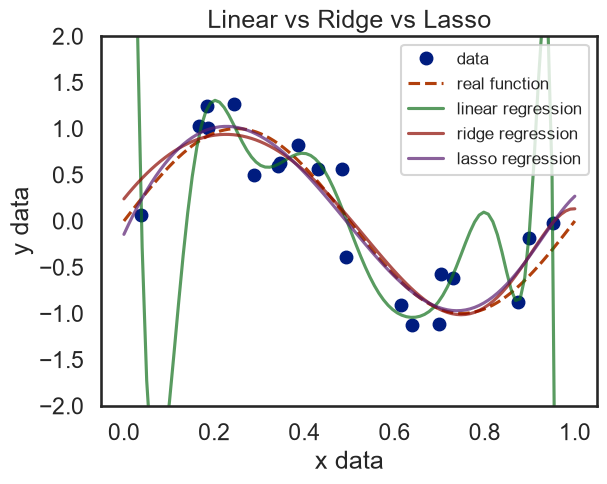

In [6]:
rr = Ridge(alpha=0.001).fit(X_poly, Y_data)
lassor = Lasso(alpha=0.0001, max_iter=100_000).fit(X_poly, Y_data)

models = {'linear regression': lr, 'ridge regression': rr, 'lasso regression': lassor}

plt.plot(X_data, Y_data, marker='o', ls='', label='data')
plt.plot(X_real, Y_real, ls='--', label='real function')
for label, model in models.items():
    plt.plot(X_real, model.predict(X_real_poly), alpha=.7, label=label)
plt.ylim(-2, 2)
plt.legend(fontsize='x-small')
plt.gca().set(xlabel='x data', ylabel='y data', title='Linear vs Ridge vs Lasso');

In [7]:
pd.DataFrame({
    'RMSE on data points': [np.sqrt(mean_squared_error(Y_data, m.predict(X_poly))) for m in models.values()],
    'RMSE vs real function': [np.sqrt(mean_squared_error(Y_real, m.predict(X_real_poly))) for m in models.values()],
}, index=list(models))

,RMSE on data points,RMSE vs real function
linear regression,0.184749,17.154590
ridge regression,0.298621,0.117298
lasso regression,0.279980,0.107482


In [8]:
coefficients = pd.DataFrame({label: model.coef_ for label, model in models.items()}).abs()

coefficients.describe()

,linear regression,ridge regression,lasso regression
count,21.000000,2.100000e+01,21.000000
mean,116545.022386,2.169397e+00,2.665181
std,81602.138436,2.900278e+00,6.772431
min,742.429428,8.851762e-12,0.000000
25%,58963.910745,4.675777e-01,0.000000
50%,99897.727318,1.017272e+00,0.000000
75%,159528.785690,2.883507e+00,0.000000
max,306452.054427,1.242963e+01,25.359652


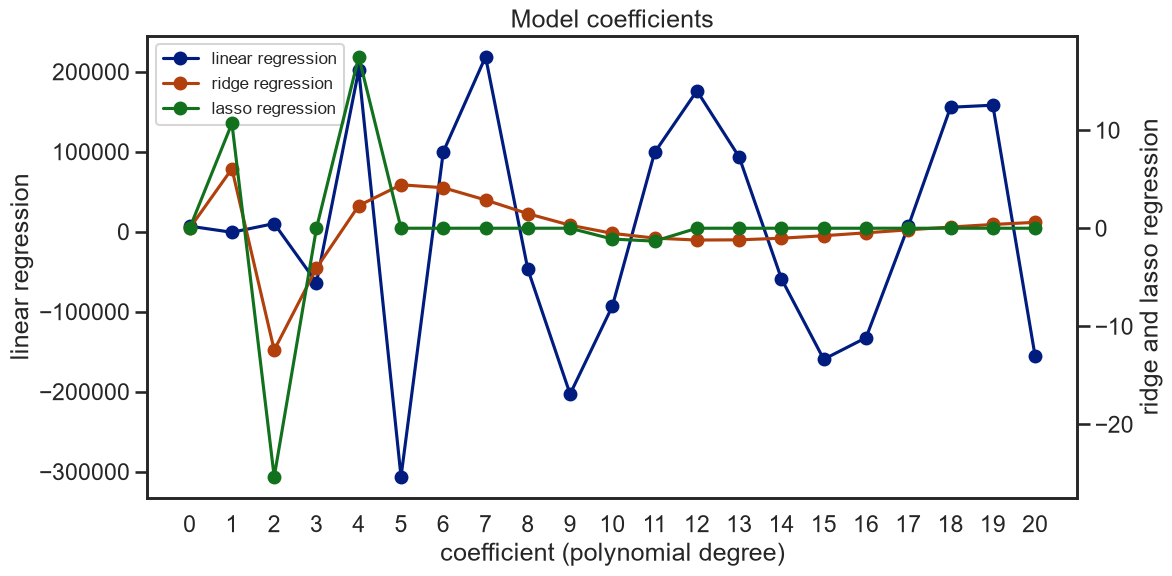

In [9]:
colors = sns.color_palette()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

ax1.plot(lr.coef_, color=colors[0], marker='o', label='linear regression')
ax2.plot(rr.coef_, color=colors[1], marker='o', label='ridge regression')
ax2.plot(lassor.coef_, color=colors[2], marker='o', label='lasso regression')

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize='x-small')

ax1.set(xlabel='coefficient (polynomial degree)', ylabel='linear regression', title='Model coefficients')
ax2.set(ylabel='ridge and lasso regression')
ax1.set_xticks(range(len(lr.coef_)));

Вывод: я обучил Ridge (alpha = 0.001) и Lasso (alpha = 0.0001) на тех же 21 признаке, что и в задании 2. На обучающих точках у них RMSE выше, чем у линейной регрессии (0.30 и 0.28 против 0.18), но относительно истинной функции RMSE всего 0.12 и 0.11 против 17.15, потому что их кривые гладкие и почти совпадают с синусоидой. У линейной регрессии модули коэффициентов в среднем около 117 000, а максимум около 306 000, у Ridge максимум 12.4, а Lasso оставил ненулевыми только несколько коэффициентов (75-й перцентиль модулей равен 0). Такие огромные коэффициенты с разными знаками почти гасят друг друга на обучающих точках, поэтому модель очень чувствительна к небольшим изменениям x и подстраивается под шум. Регуляризация штрафует большие коэффициенты: L2 их уменьшает, а L1 часть из них обнуляет, поэтому модель становится проще и лучше обобщает. Для Lasso я поставил max_iter = 100000, так как при 1000 итераций алгоритм не сходился.

## Вопрос 4

В оставшихся вопросах мы будем работать с [набором данных](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) из прошлого занятия, который основан на данных о ценах на жилье в Эймсе, штат Айова. В наборе содержится большое количество признаков — подробнее об этих признаках см. в упражнениях третьей недели.

Для начала:

* Импортируйте данные с помощью Pandas, удалите все нулевые значения и выполните кодирование категориальных переменных методом «one-hot». Для этого можно использовать либо кодировщики признаков из Scikit-learn, либо метод `get_dummies` из Pandas.
* Разделите данные на обучающую и тестовую выборки.
* Примените логарифмическое преобразование к асимметричным признакам.
* Можно попробовать выполнить масштабирование, хотя будет интересно посмотреть, насколько хорошо работает регуляризация без масштабирования признаков.

In [10]:
filepath = os.sep.join(data_path + ['Ames_Housing_Sales.csv'])
data = pd.read_csv(filepath)

data.shape

(1379, 80)

In [11]:
missing = data.isna().sum()
print('rows without missing values:', len(data.dropna()))
missing[missing > 0].sort_values(ascending=False).to_frame('missing').join(data.dtypes.rename('dtype'))

rows without missing values: 0


,missing,dtype
PoolQC,1372,str
MiscFeature,1328,str
Alley,1297,str
Fence,1114,str
MasVnrType,797,str
FireplaceQu,618,str
BsmtFinType2,427,str
BsmtExposure,426,str
BsmtCond,426,str
BsmtQual,426,str


Создайте список категориальных данных и примените к ним кодирование «one-hot». Кодировщик «one-hot» в Pandas (`get_dummies`) хорошо подходит для данных, определённых как категориальные.

In [12]:
one_hot_encode_cols = data.select_dtypes(include='str').columns.tolist()

data = pd.get_dummies(data, columns=one_hot_encode_cols, dtype=int)

len(one_hot_encode_cols), data.shape, data.isna().sum().sum()

(43, (1379, 284), np.int64(0))

Далее разделите данные на обучающий и тестовый наборы.

In [13]:
train, test = train_test_split(data, test_size=0.3, random_state=42)

train.shape, test.shape

((965, 284), (414, 284))

Есть ряд столбцов с асимметричным распределением — к ним можно применить логарифмическое преобразование. Обратите внимание, что в их число входит и `SalePrice` — наш предиктор. Однако давайте оставим его без изменений.

In [14]:
float_cols = data.select_dtypes(include='float').columns

In [15]:
skew_limit = 0.75
skew_vals = train[float_cols].skew()

skew_cols = skew_vals[skew_vals.abs() > skew_limit].sort_values(ascending=False).to_frame('Skew')

skew_cols

,Skew
MiscVal,26.915364
PoolArea,15.777668
LotArea,11.501694
LowQualFinSF,11.210638
3SsnPorch,10.150612
ScreenPorch,4.599803
BsmtFinSF2,4.466378
EnclosedPorch,3.218303
LotFrontage,3.138032
MasVnrArea,2.492814


Преобразуйте все столбцы, в которых коэффициент асимметрии превышает 0,75, за исключением столбца «SalePrice».

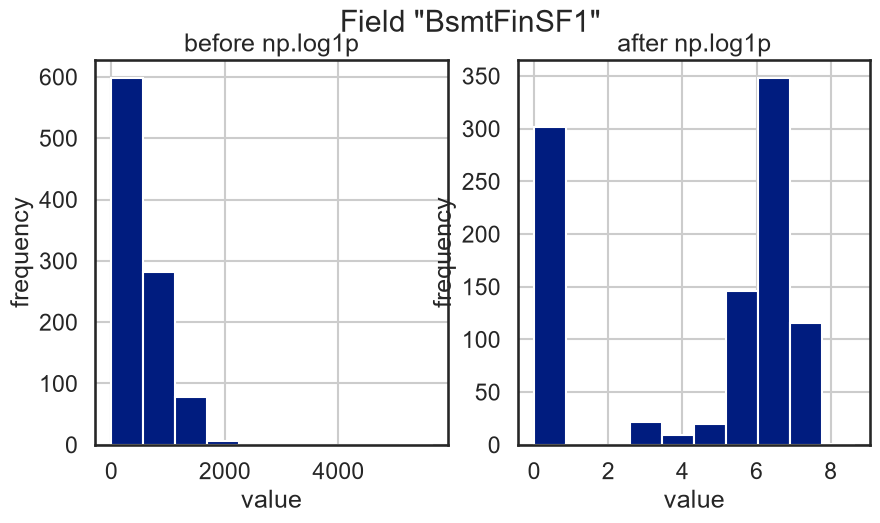

In [16]:
field = 'BsmtFinSF1'
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 5))
train[field].hist(ax=ax_before)
train[field].apply(np.log1p).hist(ax=ax_after)
ax_before.set(title='before np.log1p', ylabel='frequency', xlabel='value')
ax_after.set(title='after np.log1p', ylabel='frequency', xlabel='value')
fig.suptitle(f'Field "{field}"');

In [17]:
log_cols = skew_cols.index.drop('SalePrice')

train[log_cols] = np.log1p(train[log_cols])
test[log_cols] = np.log1p(test[log_cols])

log_cols.tolist()

['MiscVal',
 'PoolArea',
 'LotArea',
 'LowQualFinSF',
 '3SsnPorch',
 'ScreenPorch',
 'BsmtFinSF2',
 'EnclosedPorch',
 'LotFrontage',
 'MasVnrArea',
 'OpenPorchSF',
 'BsmtFinSF1',
 'TotalBsmtSF',
 '1stFlrSF',
 'GrLivArea',
 'WoodDeckSF',
 'BsmtUnfSF',
 'GarageArea',
 '2ndFlrSF']

Выделить признаки из набора предикторов.

In [18]:
feature_cols = train.columns.drop('SalePrice')
X_train = train[feature_cols].to_numpy()
y_train = train['SalePrice'].to_numpy()

X_test = test[feature_cols].to_numpy()
y_test = test['SalePrice'].to_numpy()

X_train.shape, X_test.shape, X_train.dtype

((965, 283), (414, 283), dtype('float64'))

Вывод: в Ames_Housing_Sales.csv 1379 строк и 80 столбцов, пропуски есть только в 11 категориальных столбцах, например PoolQC пропущен в 1372 строках. Удалять строки с пропусками я не стал, потому что пропуск есть в каждой строке и после dropna не осталось бы ни одной, а в этих столбцах NaN означает, что у дома нет бассейна, подвала, забора и так далее. Поэтому я закодировал 43 строковых столбца через get_dummies, где NaN превращается в нули во всех фиктивных столбцах, и после этого пропусков стало 0, а столбцов 284. Затем я разделил данные на обучающую (965 строк) и тестовую (414 строк) выборки в пропорции 70/30 с random_state = 42. Асимметрию я считал только по обучающей выборке и применил log1p к 19 столбцам, где она больше 0.75, а SalePrice оставил без изменений, как сказано в условии. Так как у log1p нет параметров, которые подбираются по данным, его можно применить к тестовой выборке без утечки данных. Масштабирование я здесь не делал, чтобы посмотреть, как регуляризация работает без него (задания 7 и 8).

## Вопрос 5

* Напишите функцию **`rmse`**, которая принимает в качестве аргументов значения истинных и прогнозируемых значений и возвращает среднеквадратичную ошибку. Используйте функцию `mean_squared_error` из библиотеки sklearn.


In [19]:
def rmse(ytrue, ypredicted):
    return np.sqrt(mean_squared_error(ytrue, ypredicted))

* Построить базовую модель линейной регрессии
* Вывести среднеквадратичную ошибку для этой модели
* Построить график сопоставления прогнозируемой и фактической цены продажи на основе модели.

In [20]:
linearRegression = LinearRegression().fit(X_train, y_train)
y_pred_test = linearRegression.predict(X_test)

linearRegression_rmse = rmse(y_test, y_pred_test)

print('test RMSE:', linearRegression_rmse)
print('train RMSE:', rmse(y_train, linearRegression.predict(X_train)))
print('max abs error on test:', np.abs(y_test - y_pred_test).max())
print('rank of X_train:', np.linalg.matrix_rank(X_train), 'of', X_train.shape[1])

test RMSE: 945962.4185782097
train RMSE: 20187.714010122625
max abs error on test: 13979734.288275223
rank of X_train: 234 of 283


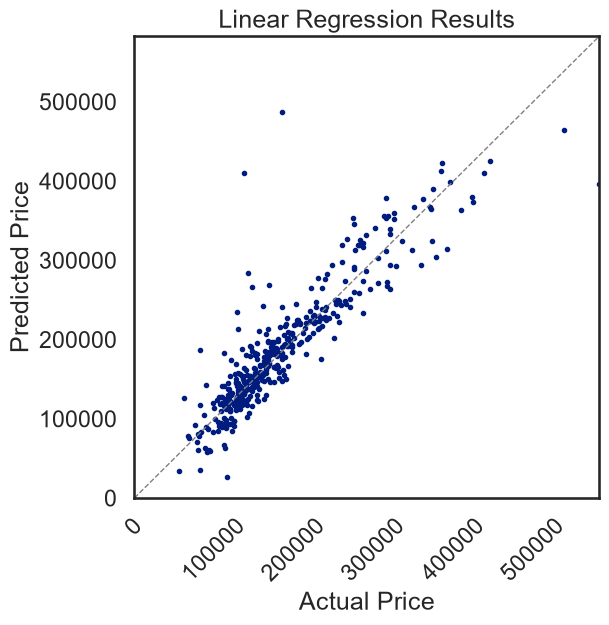

In [21]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(y_test, y_pred_test, marker='o', ls='', ms=3.0)

lim = (0, y_test.max())
ax.plot(lim, lim, color='gray', ls='--', lw=1)

ax.set(xlabel='Actual Price',
       ylabel='Predicted Price',
       xlim=lim,
       ylim=lim,
       title='Linear Regression Results')
ax.tick_params(axis='x', labelrotation=45);

Вывод: я написал функцию rmse через mean_squared_error и обучил обычную линейную регрессию на 283 признаках. RMSE на тестовой выборке получился 945 962, а на обучающей всего 20 188, то есть модель сильно переобучилась. На графике большинство точек лежит около диагонали, но несколько прогнозов вышли за его пределы, максимальная ошибка на тесте около 14 млн. Скорее всего, это из-за того, что ранг матрицы признаков 234 при 283 признаках: после one-hot кодирования часть столбцов линейно зависима, и есть редкие категории (задание 4). Поэтому коэффициенты без регуляризации получаются неустойчивыми и на некоторых новых домах дают огромные ошибки. Эту модель я дальше использую как базовую для сравнения (задания 6–8).

## Вопрос 6

В регрессии Риджа используется L2-нормализация для уменьшения величины коэффициентов. Это может быть полезно в ситуациях с высокой дисперсией. Каждая из функций регуляризации в Scikit-learn содержит версии со встроенной перекрестной валидацией.

* Постройте обычную (без перекрестной валидации) модель Риджа для диапазона значений $\alpha$ и постройте график среднеквадратичной ошибки (RMSE) с использованием созданной вами выше функции ошибки с перекрестной валидацией.
* Используйте $$[0,005; 0,05; 0,1; 0,3; 1; 3; 5; 10; 15; 30; 80]$$ в качестве диапазона значений $\alpha$.
* Затем повторите подбор моделей Риджа, используя диапазон значений $\alpha$ из предыдущего раздела. Сравните результаты.

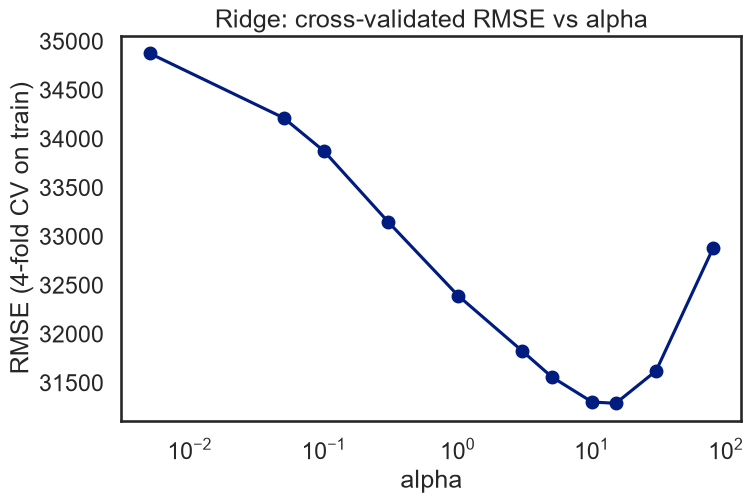

,CV RMSE
0.005,34876.032153
0.050,34214.208667
0.100,33873.731729
0.300,33150.801317
1.000,32392.946613
3.000,31826.917871
5.000,31559.514308
10.000,31302.226397
15.000,31289.014092
30.000,31621.652537


In [22]:
alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]
rmse_scorer = make_scorer(rmse, greater_is_better=False)

ridge_rmses = pd.Series(
    [-cross_val_score(Ridge(alpha=alpha), X_train, y_train, cv=4, scoring=rmse_scorer).mean() for alpha in alphas],
    index=alphas,
)

ax = ridge_rmses.plot(marker='o', logx=True, figsize=(8, 5))
ax.set(xlabel='alpha', ylabel='RMSE (4-fold CV on train)', title='Ridge: cross-validated RMSE vs alpha')
plt.show()

ridge_rmses.to_frame('CV RMSE')

Теперь рассмотрим метод `RidgeCV`. К сожалению, получить значения альфа для моделей, которые не были выбраны, не представляется возможным. Полученные значения ошибок и значения $\alpha$ очень похожи на те, что были получены выше.

In [23]:
ridgeCV = RidgeCV(alphas=alphas, cv=4, scoring=rmse_scorer).fit(X_train, y_train)

ridgeCV_rmse = rmse(y_test, ridgeCV.predict(X_test))

print(ridgeCV.alpha_, ridgeCV_rmse)

15.0 32195.778260172996


Вывод: для каждого alpha из списка я обучил обычную модель Ridge и посчитал RMSE на кросс-валидации из 4 фолдов на обучающей выборке с помощью своей функции rmse. График получился U-образным: при alpha = 0.005 RMSE 34 876, минимум 31 289 при alpha = 15, а при alpha = 80 RMSE снова растёт до 32 882. Так происходит, потому что при маленьком alpha модель почти не отличается от обычной линейной регрессии и переобучается, а при большом коэффициенты слишком сильно сжимаются и модель недообучается. RidgeCV с теми же alpha, фолдами и метрикой тоже выбрал alpha = 15, значит, оба способа дают одинаковый результат, просто RidgeCV не показывает ошибки для остальных alpha. На тестовой выборке Ridge с alpha = 15 дал RMSE 32 196, это почти в 30 раз меньше, чем у линейной регрессии (задание 5). Тестовую выборку я не использовал при выборе alpha, поэтому оценка честная, но она получена на одном разбиении.

## Вопрос 7


Подобно функции `RidgeCV`, существует также функция `LassoCV`, которая использует функцию регуляризации L1 и перекрестную валидацию. Регуляризация L1 выборочно уменьшает некоторые коэффициенты, что фактически приводит к удалению признаков.

Функция `LassoCV` не позволяет задавать функцию оценки. Однако для оценки ошибки конечной модели можно использовать созданную выше пользовательскую функцию ошибки (`rmse`).

Аналогично существует также функция ElasticNet с перекрестной валидацией — `ElasticNetCV`, представляющая собой комбинацию регуляризаций L2 и L1.

* Постройте модель Lasso с использованием перекрестной валидации и определите оптимальное значение $\alpha$ и RMSE с помощью созданной выше функции. Обратите внимание, что величина $\alpha$ может отличаться от значения для модели Ridge.
* Повторите эту процедуру для модели ElasticNet.
* Сравните результаты с помощью таблицы и/или графика.

Используйте следующие значения $\alpha$:
`[1e-5, 5e-5, 0.0001, 0.0005]`

In [24]:
alphas2 = np.array([1e-5, 5e-5, 0.0001, 0.0005])

with warnings.catch_warnings(action='ignore', category=ConvergenceWarning):
    lassoCV = LassoCV(alphas=alphas2, max_iter=50_000, cv=4).fit(X_train, y_train)

lassoCV_rmse = rmse(y_test, lassoCV.predict(X_test))

print(lassoCV.alpha_, lassoCV_rmse)

0.0005 37753.02530518537


Мы можем определить, сколько из этих характеристик остаются неравными нулю.

In [25]:
print(f'Of {lassoCV.coef_.size} coefficients, {np.count_nonzero(lassoCV.coef_)} are non-zero with Lasso.')

Of 283 coefficients, 265 are non-zero with Lasso.


Теперь попробуйте использовать метод «Elastic Net» с теми же значениями альфа, что и в методе «Lasso», и значениями l1_ratios в диапазоне от 0,1 до 0,9

In [26]:
l1_ratios = np.linspace(0.1, 0.9, 9)

with warnings.catch_warnings(action='ignore', category=ConvergenceWarning):
    elasticNetCV = ElasticNetCV(alphas=alphas2, l1_ratio=l1_ratios, max_iter=50_000, cv=4).fit(X_train, y_train)

elasticNetCV_rmse = rmse(y_test, elasticNetCV.predict(X_test))

print(elasticNetCV.alpha_, elasticNetCV.l1_ratio_, elasticNetCV_rmse)

0.0005 0.1 35009.07612625837


Сравнить результаты расчета среднеквадратичной ошибки (RMSE) для всех моделей проще всего в таблице.

In [27]:
rmse_df = pd.DataFrame(
    {'RMSE': [linearRegression_rmse, ridgeCV_rmse, lassoCV_rmse, elasticNetCV_rmse]},
    index=['Linear', 'Ridge', 'Lasso', 'ElasticNet'],
)

rmse_df

,RMSE
Linear,945962.418578
Ridge,32195.778260
Lasso,37753.025305
ElasticNet,35009.076126


Мы также можем построить график, на котором будут отображены фактические и прогнозируемые цены на жилье, как и ранее.

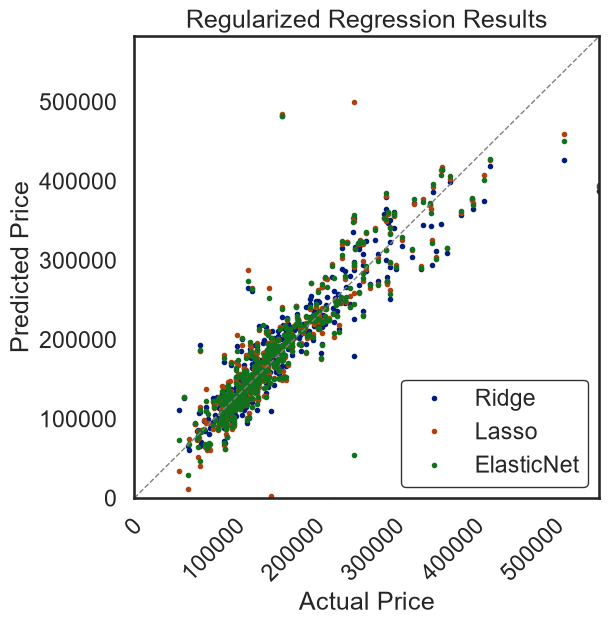

In [28]:
fig, ax = plt.subplots(figsize=(6, 6))

for label, model in {'Ridge': ridgeCV, 'Lasso': lassoCV, 'ElasticNet': elasticNetCV}.items():
    ax.plot(y_test, model.predict(X_test), marker='o', ls='', ms=3.0, label=label)

lim = (0, y_test.max())
ax.plot(lim, lim, color='gray', ls='--', lw=1)

leg = ax.legend(frameon=True)
leg.get_frame().set_edgecolor('black')
leg.get_frame().set_linewidth(1.0)

ax.set(xlabel='Actual Price',
       ylabel='Predicted Price',
       xlim=lim,
       ylim=lim,
       title='Regularized Regression Results')
ax.tick_params(axis='x', labelrotation=45);

Вывод: LassoCV и ElasticNetCV с alpha из условия выбрали alpha = 0.0005, а ElasticNet ещё l1_ratio = 0.1, на тестовой выборке RMSE получился 37 753 у Lasso и 35 009 у ElasticNet. Лучшей осталась Ridge с RMSE 32 196 (задание 6), но все три модели примерно в 25–30 раз лучше линейной регрессии, и на графике их прогнозы лежат вдоль диагонали без ошибок в миллионы, как в задании 5. Lasso обнулил только 18 коэффициентов из 283, потому что при таком маленьком alpha штраф слабый по сравнению с ошибкой, ведь цены домов порядка сотен тысяч. Выбранное alpha = 0.0005 это верхняя граница сетки из условия, поэтому, вероятно, лучшее значение больше, но с этой сеткой проверить это нельзя. ElasticNet выбрал самую маленькую долю L1, то есть он ближе всего к Ridge, и это согласуется с тем, что Ridge здесь работает лучше. Для всех моделей я взял 4 фолда, как у RidgeCV, чтобы условия сравнения были одинаковыми, а предупреждения о несходимости отключил только на время обучения Lasso и ElasticNet, так как без масштабирования координатный спуск не успевает сойтись даже за 50 000 итераций, и их результаты, скорее всего, немного неточные. Сравнение сделано на одном разбиении, поэтому разница в несколько тысяч между моделями не очень надёжная.

## Вопрос 8

В этом упражнении рассмотрим метод стохастического градиентного спуска (SGD).
Напомним, что линейные модели в целом чувствительны к масштабированию.
Однако метод SGD *очень* чувствителен к масштабированию.
Кроме того, высокое значение скорости обучения может привести к расхождению алгоритма, тогда как слишком низкое значение может привести к слишком длительному процессу сходимости.

* Постройте модель со стохастическим градиентным спуском без штрафа регуляризации (соответствующий параметр — `penalty`).
* Теперь постройте модели со стохастическим градиентным спуском с каждым из трёх штрафов (L2, L1, Elastic Net), используя значения параметров, определённые выше с помощью перекрёстной валидации.
* Не масштабируйте данные перед построением модели.
* Сравните результаты с теми, которые были получены без использования метода стохастического градиентного спуска.

In [29]:
model_parameters_dict = {
    'Linear': {'penalty': None},
    'Ridge': {'penalty': 'l2', 'alpha': ridgeCV.alpha_ / len(X_train)},
    'Lasso': {'penalty': 'l1', 'alpha': lassoCV.alpha_},
    'ElasticNet': {'penalty': 'elasticnet', 'alpha': elasticNetCV.alpha_, 'l1_ratio': elasticNetCV.l1_ratio_},
}


def sgd_rmses(X_fit, X_eval, **sgd_params):
    return pd.Series({
        label: rmse(y_test, SGDRegressor(random_state=42, **sgd_params, **params).fit(X_fit, y_train).predict(X_eval))
        for label, params in model_parameters_dict.items()
    })


rmse_df['RMSE-SGD'] = sgd_rmses(X_train, X_test)
rmse_df

,RMSE,RMSE-SGD
Linear,945962.418578,5.045388e+15
Ridge,32195.778260,1.826911e+14
Lasso,37753.025305,5.046198e+15
ElasticNet,35009.076126,6.377489e+14


Обратите внимание, насколько велики значения ошибок! Алгоритм расходится. Это может быть связано со слишком высоким коэффициентом масштабирования и/или слишком высокой скоростью обучения. Давайте скорректируем скорость обучения и посмотрим, что произойдет.

In [30]:
rmse_df['RMSE-SGD-learningrate'] = sgd_rmses(X_train, X_test, eta0=1e-7)

print('RMSE of constant prediction (train mean):', rmse(y_test, np.full_like(y_test, y_train.mean())))
rmse_df

RMSE of constant prediction (train mean): 77764.79870012453


,RMSE,RMSE-SGD,RMSE-SGD-learningrate
Linear,945962.418578,5.045388e+15,74725.096866
Ridge,32195.778260,1.826911e+14,74725.101519
Lasso,37753.025305,5.046198e+15,74725.096870
ElasticNet,35009.076126,6.377489e+14,74725.097001


Now let's scale our training data and try again.

* Fit a `MinMaxScaler` to `X_train` create a variable `X_train_scaled`.
* Using the scaler, transform `X_test` and create a variable `X_test_scaled`.
* Apply the same versions of SGD to them and compare the results. Don't pass in a eta0 this time.

In [31]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rmse_df['RMSE-SGD-scaled'] = sgd_rmses(X_train_scaled, X_test_scaled)
rmse_df

,RMSE,RMSE-SGD,RMSE-SGD-learningrate,RMSE-SGD-scaled
Linear,945962.418578,5.045388e+15,74725.096866,32866.698689
Ridge,32195.778260,1.826911e+14,74725.101519,32663.893364
Lasso,37753.025305,5.046198e+15,74725.096870,32866.693517
ElasticNet,35009.076126,6.377489e+14,74725.097001,33204.402118


Вывод: в первой части я обучил SGDRegressor без штрафа и со штрафами L2, L1 и Elastic Net на немасштабированных данных, и RMSE получился от 1.8·10¹⁴ до 5·10¹⁵, то есть алгоритм разошёлся, потому что признаки очень разного масштаба (годы около 2000, фиктивные признаки 0 или 1) и шаг по умолчанию для них слишком большой. Для Ridge я передал alpha = 15 / 965, так как Ridge не делит ошибку на число объектов, а SGD делит, и без этого штраф был бы примерно в 965 раз сильнее.

Во второй части с eta0 = 1e-7 алгоритм уже не расходится, но у всех четырёх моделей RMSE около 74 725, почти как у прогноза средним значением (77 765). Скорее всего, шаг настолько маленький, что веса почти не меняются и обучение быстро останавливается, поэтому модель недообучается и штраф ни на что не влияет.

В третьей части я обучил MinMaxScaler только на обучающей выборке и применил его к тестовой, и SGD с параметрами по умолчанию дал RMSE от 32 664 до 33 204, почти как Ridge (32 196, задание 6). Даже SGD без штрафа получил 32 867, а обычная линейная регрессия 945 962 (задание 5), вероятно, потому что SGD начинает с нулевых весов и останавливается раньше, чем они становятся огромными. Разница между штрафами маленькая, потому что alpha подбирались для немасштабированных данных, и для масштабированных их, скорее всего, надо подбирать заново.